# Лабораторная работа №3. Проверка статистических гипотез и ANOVA

**Дисциплина:** Интеллектуальные методы анализа данных
**Вариант 3:** Breast Cancer Wisconsin Dataset (сравнение признаков по диагнозу)
**Выполнила:** Петров Ю. П., группа ПМ-24-1

## Цель работы
Освоить параметрические и непараметрические критерии проверки гипотез, однофакторный и двухфакторный дисперсионный анализ (ANOVA) и пост-хок сравнения; научиться формулировать нулевую и альтернативную гипотезы, проверять предпосылки критериев и интерпретировать результаты.

## Как оформлена работа
Код написан с помощью нейросети. Перед каждым блоком кода приведён промпт, по которому я его получила. После результата идёт блок «Описание»: в нём я записала, что делает код и какой вывод следует из результата. Все ячейки уже выполнены.

## Подключение библиотек

**Промпт:** Я делаю лабораторную работу по проверке статистических гипотез и ANOVA в Google Colab. Подскажи, какие библиотеки нужны для t-критериев, критерия Манна–Уитни, ANOVA, пост-хок тестов (Тьюки, Даннет), расчёта мощности и построения графиков, и напиши код импорта с короткими комментариями.

In [1]:
import warnings
import numpy as np                                     # массивы и математика
import pandas as pd                                    # таблицы
import matplotlib.pyplot as plt                        # графики
from scipy import stats                                # статистические критерии

import statsmodels.formula.api as smf                  # модели в виде формулы y ~ x
from statsmodels.stats.anova import anova_lm           # таблица ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd   # пост-хок тест Тьюки
from statsmodels.stats.oneway import anova_oneway      # ANOVA Уэлча
from statsmodels.stats.power import TTestIndPower, FTestAnovaPower   # расчёт мощности
from sklearn.datasets import load_breast_cancer        # сам набор данных

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110})
rng = np.random.default_rng(42)                        # генератор случайных чисел с фиксированным зерном
print('Библиотеки подключены')

Библиотеки подключены


**Описание.** Ячейка подключает библиотеки. `pandas` нужен для таблиц, `scipy.stats` содержит сами критерии (Шапиро–Уилка, Левена, Стьюдента, Манна–Уитни и другие), `statsmodels` строит модели ANOVA и считает мощность, `matplotlib` рисует графики. Зерно генератора случайных чисел (42) задано, чтобы при повторном запуске результаты совпадали.

## Загрузка и подготовка данных

**Промпт:** Мой вариант — Breast Cancer Wisconsin (сравнение признаков по диагнозу). Напиши код, который загружает этот набор из sklearn в pandas.DataFrame, добавляет столбец diagnosis со значениями malignant и benign (в sklearn 0 означает злокачественную опухоль), заменяет пробелы в названиях столбцов на подчёркивания и создаёт фактор size: три равные по численности группы по признаку mean_radius с названиями «малый», «средний», «крупный». В конце выведи число наблюдений, число пропусков, число объектов в каждой группе и границы групп по размеру.

In [2]:
d = load_breast_cancer(as_frame=True)
df = d.frame.copy()
df['diagnosis'] = np.where(df['target'] == 0, 'malignant', 'benign')   # в sklearn 0 = злокачественная
df = df.rename(columns=lambda c: c.replace(' ', '_'))                  # 'mean radius' -> 'mean_radius'

# Фактор «размер ядра»: три группы равной численности по среднему радиусу (терцили)
df['size'] = pd.qcut(df['mean_radius'], 3, labels=['малый', 'средний', 'крупный']).astype(str)

dg, sz = ['benign', 'malignant'], ['малый', 'средний', 'крупный']
Gd = {g: df.loc[df.diagnosis == g, 'mean_radius'].values for g in dg}         # радиус по диагнозам
Gs = {s: df.loc[df['size'] == s, 'mean_concavity'].values for s in sz}       # вогнутость по размеру ядра

print('Наблюдений:', len(df), '| пропусков:', int(df.isna().sum().sum()))
print(df['diagnosis'].value_counts().to_dict())
print(df['size'].value_counts().to_dict())
print('Границы групп размера:', list(pd.qcut(df['mean_radius'], 3).cat.categories))

Наблюдений: 569 | пропусков: 0
{'benign': 357, 'malignant': 212}
{'малый': 191, 'крупный': 190, 'средний': 188}
Границы групп размера: [Interval(6.9799999999999995, 12.25, closed='right'), Interval(12.25, 14.773, closed='right'), Interval(14.773, 28.11, closed='right')]


**Описание.** В наборе 569 наблюдений (пациенток) и 30 числовых признаков, вычисленных по изображениям ядер клеток; пропусков нет. Доброкачественных опухолей (benign) 357, злокачественных (malignant) 212.

Диагноз имеет только два уровня, а для пост-хок сравнений нужно не меньше трёх групп. Поэтому я добавила фактор `size`: разбила наблюдения на три группы равной численности по среднему радиусу (191, 188 и 190 наблюдений). Границы групп: до 12,25 — малый размер, от 12,25 до 14,77 — средний, больше 14,77 — крупный. Это искусственный фактор: он построен из данных, а не задан экспериментом.

В работе я сравниваю три вещи: радиус ядра по диагнозам (две группы), вогнутость контура `mean_concavity` по трём группам размера (однофакторный ANOVA) и вогнутость одновременно по диагнозу и размеру (двухфакторный ANOVA).

## Часть 1. Описательная статистика и проверка предпосылок

**Промпт:** Для признака mean_radius по диагнозам и для признака mean_concavity по группам размера посчитай количество наблюдений, среднее, медиану, стандартное отклонение, первый и третий квартили, 95% доверительный интервал для среднего, асимметрию и p-value критерия Шапиро–Уилка. Результат выведи одной таблицей.

In [3]:
def describe(v):
    n = len(v); m = v.mean(); sd = v.std(ddof=1)                   # ddof=1: выборочное стандартное отклонение
    h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)                # полуширина 95% доверительного интервала
    return {'n': n, 'среднее': m, 'медиана': np.median(v), 'СКО': sd,
            'Q1': np.percentile(v, 25), 'Q3': np.percentile(v, 75),
            'ДИ от': m - h, 'ДИ до': m + h,
            'асимметрия': stats.skew(v), 'Шапиро p': stats.shapiro(v).pvalue}

t1 = pd.DataFrame({f'mean_radius, {g}': describe(Gd[g]) for g in dg}).T
t2 = pd.DataFrame({f'mean_concavity, {s}': describe(Gs[s]) for s in sz}).T
pd.concat([t1, t2]).round(4)

,n,среднее,медиана,СКО,Q1,Q3,ДИ от,ДИ до,асимметрия,Шапиро p
"mean_radius, benign",357.0,12.1465,12.2000,1.7805,11.0800,13.3700,11.9612,12.3319,-0.0834,0.6680
"mean_radius, malignant",212.0,17.4628,17.3250,3.2040,15.0750,19.5900,17.0291,17.8966,0.4983,0.0019
"mean_concavity, малый",191.0,0.0457,0.0333,0.0516,0.0185,0.0563,0.0384,0.0531,3.4722,0.0000
"mean_concavity, средний",188.0,0.0640,0.0471,0.0513,0.0281,0.0937,0.0566,0.0713,1.3947,0.0000
"mean_concavity, крупный",190.0,0.1567,0.1491,0.0818,0.0989,0.2032,0.1450,0.1684,0.7697,0.0000


**Описание.** Функция `describe` считает для массива значений основные характеристики. Стандартное отклонение берётся с `ddof=1` (делим на n − 1), так как это выборочная оценка. Доверительный интервал среднего строится по распределению Стьюдента.

Средний радиус равен 12,15 у benign и 17,46 у malignant, доверительные интервалы средних не пересекаются. По критерию Шапиро–Уилка для радиуса benign p = 0,668 (нормальность не отвергается), для malignant p = 0,002 (небольшое отклонение, асимметрия 0,50). Вогнутость сильно скошена вправо во всех трёх группах (асимметрия 3,47; 1,39 и 0,77), p ≪ 0,05. При нескольких сотнях наблюдений критерий Шапиро–Уилка отвергает даже небольшие отклонения, поэтому дополнительно я смотрю на графики.

**Промпт:** Проверь однородность дисперсий для mean_radius по двум диагнозам и для mean_concavity по трём группам размера критериями Левена (по среднему и по медиане) и Бартлетта. Выведи p-value каждого критерия.

In [4]:
def var_tests(groups):
    # H0: дисперсии всех групп равны
    return pd.Series({'Левен (по среднему)': stats.levene(*groups, center='mean').pvalue,
                      'Левен (по медиане)': stats.levene(*groups, center='median').pvalue,
                      'Бартлетт': stats.bartlett(*groups).pvalue})

print('mean_radius по диагнозам:')
print(var_tests(list(Gd.values())).apply(lambda p: f'{p:.1e}').to_string())
print('\nmean_concavity по размеру:')
print(var_tests(list(Gs.values())).apply(lambda p: f'{p:.1e}').to_string())

mean_radius по диагнозам:
Левен (по среднему)    3.9e-20
Левен (по медиане)     5.3e-20
Бартлетт               1.5e-22

mean_concavity по размеру:
Левен (по среднему)    4.5e-13
Левен (по медиане)     1.2e-12
Бартлетт               2.7e-13


**Описание.** Нулевая гипотеза всех трёх критериев: дисперсии групп равны. Критерий Левена по медиане (вариант Брауна–Форсайта) устойчивее к отклонениям от нормальности, критерий Бартлетта к ним чувствителен.

Во всех случаях p ≪ 0,05, то есть дисперсии различаются. Стандартное отклонение радиуса равно 1,78 у benign и 3,20 у malignant (в 1,8 раза больше), у вогнутости по группам размера 0,052; 0,051 и 0,082. Равенство дисперсий — условие классических критериев (Стьюдента и обычного ANOVA), поэтому дальше я использую критерий Уэлча и ранговые критерии и сравниваю результаты.

**Промпт:** Построй четыре графика в одну строку: диаграмма размаха mean_radius по диагнозам, два Q-Q графика для радиуса (отдельно для benign и malignant) и диаграмма размаха mean_concavity по группам размера. Подпиши оси на русском языке.

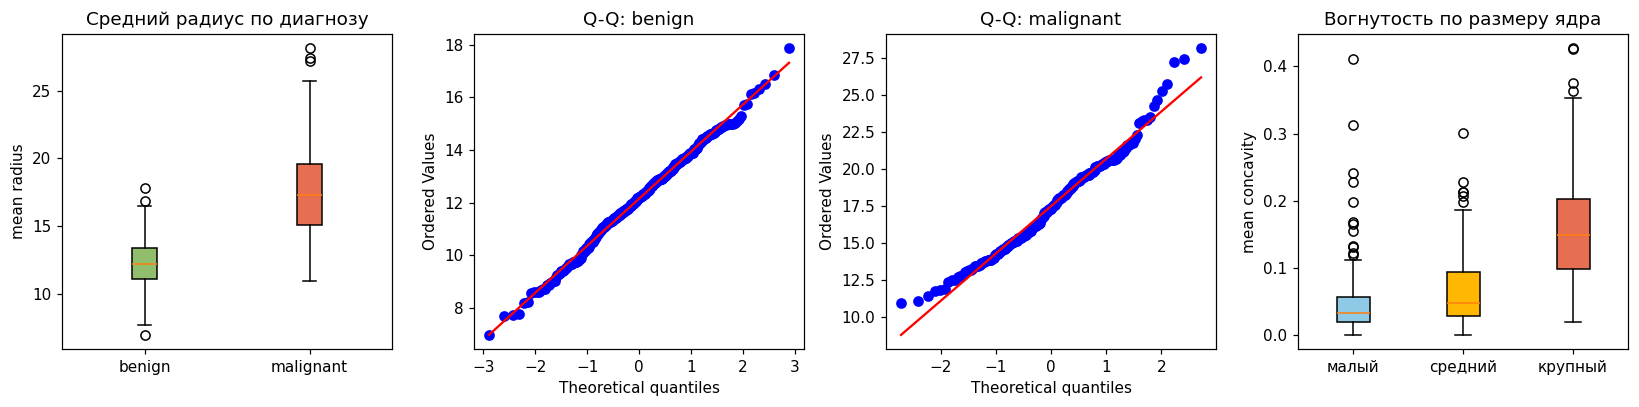

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))

bp = ax[0].boxplot([Gd[g] for g in dg], patch_artist=True)
ax[0].set_xticklabels(dg)
for patch, c in zip(bp['boxes'], ['#90be6d', '#e76f51']):
    patch.set_facecolor(c)
ax[0].set_ylabel('mean radius'); ax[0].set_title('Средний радиус по диагнозу')

for a, g in zip(ax[1:3], dg):
    stats.probplot(Gd[g], dist='norm', plot=a)                   # Q-Q график относительно нормального закона
    a.set_title(f'Q-Q: {g}')

bp = ax[3].boxplot([Gs[s] for s in sz], patch_artist=True)
ax[3].set_xticklabels(sz)
for patch, c in zip(bp['boxes'], ['#8ecae6', '#ffb703', '#e76f51']):
    patch.set_facecolor(c)
ax[3].set_ylabel('mean concavity'); ax[3].set_title('Вогнутость по размеру ядра')
plt.tight_layout(); plt.show()

**Описание.** На диаграмме размаха ящик показывает интервал от первого до третьего квартиля, линия внутри ящика — медиану, точки за усами — выбросы. Q-Q график сравнивает квантили данных с квантилями нормального распределения: чем ближе точки к прямой, тем ближе распределение к нормальному.

Для радиуса benign точки почти лежат на прямой, у malignant на краях есть небольшое отклонение. Диаграмма вогнутости показывает много выбросов вверх, что соответствует правой асимметрии.

## Часть 2. Проверка гипотез для двух групп

**Промпт:** Сравни группы benign и malignant по признакам mean_radius и mean_fractal_dimension. Для каждого признака выполни t-критерий Стьюдента, t-критерий Уэлча и критерий Манна–Уитни, посчитай d Коэна с доверительным интервалом и ранговую бисериальную корреляцию. Выведи разность средних с 95% доверительным интервалом. В конце проверь, что F из дисперсионного анализа для двух групп равен квадрату статистики t Стьюдента.

Гипотезы: H0: μ(benign) = μ(malignant), H1: μ(benign) ≠ μ(malignant), уровень значимости α = 0,05.

In [6]:
def two_sample(feature):
    a = df.loc[df.diagnosis == 'benign', feature].values
    b = df.loc[df.diagnosis == 'malignant', feature].values
    n1, n2 = len(a), len(b)
    tS = stats.ttest_ind(b, a, equal_var=True)                  # Стьюдент
    tW = stats.ttest_ind(b, a, equal_var=False)                 # Уэлч
    mw = stats.mannwhitneyu(b, a, alternative='two-sided')      # Манн–Уитни
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))   # объединённое СКО
    cd = (b.mean() - a.mean()) / sp                             # d Коэна
    se_d = np.sqrt((n1 + n2) / (n1 * n2) + cd ** 2 / (2 * (n1 + n2)))
    rbc = 2 * mw.statistic / (n1 * n2) - 1                      # ранговая бисериальная корреляция
    diff = b.mean() - a.mean()
    se_diff = np.sqrt(a.var(ddof=1) / n1 + b.var(ddof=1) / n2)
    h = stats.t.ppf(.975, tW.df) * se_diff
    print(f'--- {feature} ---')
    print(f'Средние: benign {a.mean():.4f}, malignant {b.mean():.4f}; разность {diff:.4f} (95% ДИ [{diff - h:.4f}; {diff + h:.4f}])')
    print(f'Стьюдент:   t({n1 + n2 - 2}) = {tS.statistic:.2f}, p = {tS.pvalue:.1e}')
    print(f'Уэлч:       t({tW.df:.1f}) = {tW.statistic:.2f}, p = {tW.pvalue:.1e}')
    print(f'Манн–Уитни: U = {mw.statistic:.1f}, p = {mw.pvalue:.1e}')
    print(f'd Коэна = {cd:.2f} (95% ДИ [{cd - 1.96 * se_d:.2f}; {cd + 1.96 * se_d:.2f}]), r = {rbc:.2f}')

two_sample('mean_radius')
two_sample('mean_fractal_dimension')

F_aov = smf.ols('mean_radius ~ C(diagnosis)', data=df).fit().fvalue
t_st = stats.ttest_ind(Gd['malignant'], Gd['benign']).statistic
print(f'\nF дисперсионного анализа = {F_aov:.2f}, t Стьюдента в квадрате = {t_st ** 2:.2f}')

--- mean_radius ---
Средние: benign 12.1465, malignant 17.4628; разность 5.3163 (95% ДИ [4.8452; 5.7874])
Стьюдент:   t(567) = 25.44, p = 8.5e-96
Уэлч:       t(289.7) = 22.21, p = 1.7e-64
Манн–Уитни: U = 70955.0, p = 2.7e-68
d Коэна = 2.21 (95% ДИ [1.99; 2.42]), r = 0.88
--- mean_fractal_dimension ---
Средние: benign 0.0629, malignant 0.0627; разность -0.0002 (95% ДИ [-0.0014; 0.0011])
Стьюдент:   t(567) = -0.31, p = 7.6e-01
Уэлч:       t(403.6) = -0.30, p = 7.7e-01
Манн–Уитни: U = 36671.5, p = 5.4e-01
d Коэна = -0.03 (95% ДИ [-0.20; 0.14]), r = -0.03

F дисперсионного анализа = 646.98, t Стьюдента в квадрате = 646.98


**Описание.** Функция `two_sample` выполняет три критерия для одного признака. Критерий Стьюдента использует объединённую дисперсию и предполагает её равенство, критерий Уэлча считает дисперсию каждой группы отдельно, критерий Манна–Уитни сравнивает ранги и не требует нормальности. Размер эффекта — d Коэна (разность средних в единицах объединённого стандартного отклонения).

Результаты для `mean_radius`: у malignant радиус больше на 5,32 (95% ДИ [4,85; 5,79]). Все три критерия отвергают H0 (p < 0,001), d = 2,21 — очень большой эффект (порог «большого» эффекта 0,8), ранговая бисериальная корреляция 0,88. Статистики Стьюдента и Уэлча различаются (t = 25,44 при 567 степенях свободы и t = 22,21 при 289,7), потому что дисперсии (1,78² и 3,20²) и объёмы групп (357 и 212) неравны; корректнее здесь критерий Уэлча, вывод при этом одинаковый.

Результаты для `mean_fractal_dimension`: средние практически совпадают (0,0629 и 0,0627), p = 0,76 (Стьюдент), 0,77 (Уэлч) и 0,54 (Манн–Уитни), поэтому H0 не отвергается. Значение d = −0,03 с узким интервалом [−0,20; 0,14], значит эффект, если он есть, пренебрежимо мал. Отсутствие значимости само по себе не доказывает равенство средних, это показывает узкий доверительный интервал.

Проверка в конце ячейки: F дисперсионного анализа для двух групп (646,98) равен квадрату t Стьюдента, то есть ANOVA с двумя группами — это тот же t-критерий.

**Промпт:** Для парных данных возьми два измерения одного и того же ядра у каждой пациентки: worst_radius и mean_radius. Выполни парный t-критерий и критерий Уилкоксона, посчитай d_z, проверь нормальность разностей критерием Шапиро–Уилка и построй график: диаграммы размаха радиуса и фрактальной размерности по диагнозам, гистограмму разностей и Q-Q график разностей.

n = 569, средняя разность = 2.142, медиана = 1.520, асимметрия = 1.90
Шапиро для разностей: W = 0.803, p = 1.1e-25
Парный t:  t(568) = 30.80, p = 3.1e-123
Уилкоксон: W = 0, p = 1.5e-94
d_z = 1.29


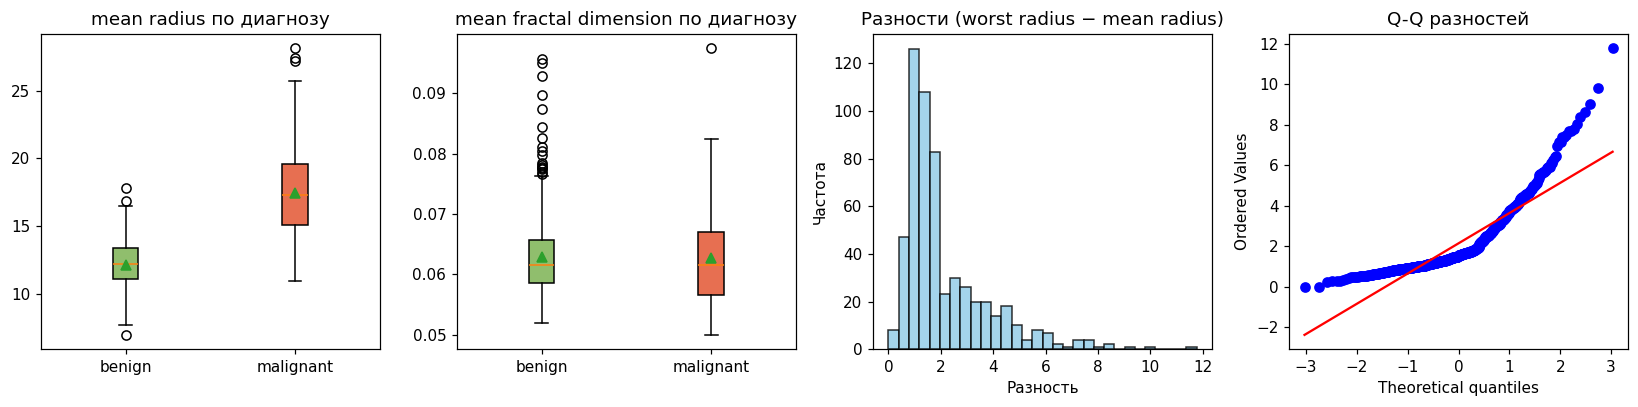

In [7]:
x1, x2 = df['worst_radius'].values, df['mean_radius'].values
dd = x1 - x2                                      # разности внутри пар

tp = stats.ttest_rel(x1, x2)                      # парный t-критерий
wl = stats.wilcoxon(x1, x2)                       # критерий Уилкоксона
dz = dd.mean() / dd.std(ddof=1)                   # размер эффекта для парных данных
sw = stats.shapiro(dd)

print(f'n = {len(dd)}, средняя разность = {dd.mean():.3f}, медиана = {np.median(dd):.3f}, асимметрия = {stats.skew(dd):.2f}')
print(f'Шапиро для разностей: W = {sw.statistic:.3f}, p = {sw.pvalue:.1e}')
print(f'Парный t:  t({len(dd) - 1}) = {tp.statistic:.2f}, p = {tp.pvalue:.1e}')
print(f'Уилкоксон: W = {wl.statistic:.0f}, p = {wl.pvalue:.1e}')
print(f'd_z = {dz:.2f}')

fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, feat in [(ax[0], 'mean_radius'), (ax[1], 'mean_fractal_dimension')]:
    bp = a.boxplot([df.loc[df.diagnosis == g, feat] for g in dg], patch_artist=True, showmeans=True)
    a.set_xticklabels(dg)
    for patch, c in zip(bp['boxes'], ['#90be6d', '#e76f51']):
        patch.set_facecolor(c)
    a.set_title(feat.replace('_', ' ') + ' по диагнозу')
ax[2].hist(dd, bins=30, edgecolor='black', alpha=0.8, color='#8ecae6')
ax[2].set_title('Разности (worst radius − mean radius)'); ax[2].set_xlabel('Разность'); ax[2].set_ylabel('Частота')
stats.probplot(dd, dist='norm', plot=ax[3]); ax[3].set_title('Q-Q разностей')
plt.tight_layout(); plt.show()

**Описание.** Парные данные — это два измерения одного объекта; анализируются разности внутри пар. H0: средняя разность равна нулю. Парный t-критерий требует примерной нормальности разностей, критерий Уилкоксона — ранговый аналог без этого требования.

Средняя разность равна 2,14, медиана 1,52. Разности сильно скошены вправо (асимметрия 1,90, критерий Шапиро–Уилка p ≈ 10⁻²⁵), то есть условие парного t-критерия нарушено, и среднее заметно больше медианы. Оба критерия отвергают H0: t(568) = 30,80, p < 0,001; W = 0, p < 0,001; d_z = 1,29. Значение W = 0 означает, что все разности положительны (наибольший радиус по определению не меньше среднего). Результат тривиален по смыслу, но на нём видна процедура парных критериев; надёжнее здесь критерий Уилкоксона.

Итог части 2: параметрические и непараметрические критерии привели к одинаковым выводам во всех сравнениях.

## Часть 3. Однофакторный ANOVA

**Промпт:** Построй однофакторный ANOVA для mean_concavity по фактору size через statsmodels. Выведи таблицу с суммами квадратов, степенями свободы, средними квадратами, F и p-value, посчитай eta², omega² и f Коэна.

Гипотезы: H0: μ(малый) = μ(средний) = μ(крупный), H1: хотя бы одно среднее отличается. Идея метода: общая изменчивость раскладывается на межгрупповую и внутригрупповую, а статистика F равна отношению средних квадратов (между группами к внутри групп).

In [8]:
m1 = smf.ols("mean_concavity ~ C(size, Treatment(reference='малый'))", data=df).fit()
at = anova_lm(m1, typ=1)
k = at.index[0]
ssb, ssw = at.loc[k, 'sum_sq'], at.loc['Residual', 'sum_sq']
dfb, dfw = int(at.loc[k, 'df']), int(at.loc['Residual', 'df'])
msb, msw = ssb / dfb, ssw / dfw
F1, p1 = at.loc[k, 'F'], at.loc[k, 'PR(>F)']

table = pd.DataFrame({'Источник': ['Между группами', 'Внутри групп', 'Всего'],
                      'SS': [ssb, ssw, ssb + ssw], 'df': [dfb, dfw, dfb + dfw],
                      'MS': [msb, msw, np.nan], 'F': [F1, np.nan, np.nan], 'p-value': [p1, np.nan, np.nan]})
print(table.round(4).to_string(index=False))

sst = ssb + ssw
eta2 = ssb / sst                                   # доля изменчивости, объяснённая фактором
omega2 = (ssb - dfb * msw) / (sst + msw)           # поправленная оценка
cf = np.sqrt(eta2 / (1 - eta2))                    # f Коэна
print(f'\neta² = {eta2:.3f}, omega² = {omega2:.3f}, f Коэна = {cf:.2f}')

      Источник     SS  df     MS        F  p-value
Между группами 1.3463   2 0.6731 168.3261      0.0
  Внутри групп 2.2635 566 0.0040      NaN      NaN
         Всего 3.6098 568    NaN      NaN      NaN

eta² = 0.373, omega² = 0.370, f Коэна = 0.77


**Описание.** Ячейка строит модель, в которой вогнутость зависит от группы размера, и выводит таблицу ANOVA: сумму квадратов между группами (SS между), внутри групп (SS внутри), степени свободы, средние квадраты (MS = SS / df) и F = MS между / MS внутри. Далее считаются размеры эффекта.

F(2; 566) = 168,33, p ≈ 4,3·10⁻⁵⁸, поэтому H0 о равенстве средних отвергается. Значение η² = 0,373: размер ядра объясняет около 37% изменчивости вогнутости, остальные 63% приходятся на разброс внутри групп. Значение ω² = 0,370 немного меньше η², так как η² слегка завышает эффект. f = 0,77, что выше порога «большого» эффекта (0,4).

**Промпт:** Проверь предпосылки этого ANOVA: нормальность остатков критерием Шапиро–Уилка, асимметрию и эксцесс остатков. Затем выполни ANOVA Уэлча (без предположения о равенстве дисперсий) и непараметрический критерий Краскела–Уоллиса, посчитай его размер эффекта.

In [9]:
res = m1.resid                                     # остатки = значение минус среднее своей группы
sw = stats.shapiro(res)
print(f'Шапиро для остатков: W = {sw.statistic:.3f}, p = {sw.pvalue:.1e}; асимметрия = {stats.skew(res):.2f}, эксцесс = {stats.kurtosis(res):.2f}')

w_ = anova_oneway([Gs[s] for s in sz], use_var='unequal', welch_correction=True)
print(f'ANOVA Уэлча: F({w_.df_num:.0f}; {w_.df_denom:.1f}) = {w_.statistic:.1f}, p = {w_.pvalue:.1e}')

kw = stats.kruskal(*Gs.values())
print(f'Краскел–Уоллис: H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, eta²_H = {(kw.statistic - 3 + 1) / (len(df) - 3):.3f}')

Шапиро для остатков: W = 0.904, p = 2.1e-18; асимметрия = 1.44, эксцесс = 4.12
ANOVA Уэлча: F(2; 365.9) = 128.7, p = 4.9e-43
Краскел–Уоллис: H = 231.8, p = 4.6e-51, eta²_H = 0.406


**Описание.** Остатки модели не нормальны (W = 0,905, p ≈ 10⁻¹⁸, асимметрия 1,44), а дисперсии групп неоднородны (часть 1). Условия классического ANOVA нарушены, поэтому я проверила результат двумя способами. ANOVA Уэлча не требует равенства дисперсий: F(2; 365,9) = 128,7, p < 0,001. Критерий Краскела–Уоллиса работает с рангами: H = 231,8, p < 0,001. Оба метода подтверждают вывод ANOVA, значит нарушение предпосылок результат не меняет.

**Промпт:** Выполни пост-хок сравнения для трёх групп размера: критерий Тьюки для всех пар, поправку Бонферрони (парные t-критерии Уэлча, p умножается на число сравнений) и критерий Даннета с контрольной группой «малый». Разности сделай в виде «больший размер минус меньший», чтобы они были положительными.

In [10]:
order = {'малый': 0, 'средний': 1, 'крупный': 2}

# критерий Тьюки (все пары)
tuk = pairwise_tukeyhsd(df['mean_concavity'], df['size'], alpha=0.05)
rows = []
for r in tuk.summary().data[1:]:
    g1, g2, dif, p, lo, hi = r[0], r[1], float(r[2]), float(r[3]), float(r[4]), float(r[5])
    if order[g1] > order[g2]:                      # приводим к виду «больший размер − меньший»
        big, base, dif, lo, hi = g1, g2, -dif, -hi, -lo
    else:
        big, base = g2, g1
    rows.append({'пара': f'{big} − {base}', 'big': big, 'base': base, 'разность': dif, 'Тьюки p': p, 'ДИ от': lo, 'ДИ до': hi})
tk = pd.DataFrame(rows).sort_values('big', key=lambda s: s.map(order)).reset_index(drop=True)

# поправка Бонферрони: t-критерии Уэлча, p умножаем на число сравнений (3)
tk['Бонферрони p'] = [min(1, stats.ttest_ind(Gs[b], Gs[a], equal_var=False).pvalue * 3) for a, b in zip(tk['base'], tk['big'])]
print(tk[['пара', 'разность', 'ДИ от', 'ДИ до', 'Тьюки p', 'Бонферрони p']].round(4).to_string(index=False))

# критерий Даннета: сравнение с контрольной группой «малый»
dn = stats.dunnett(Gs['средний'], Gs['крупный'], control=Gs['малый'])
ci = dn.confidence_interval()
print('\nДаннет (контроль = малый):')
for i, g in enumerate(['средний', 'крупный']):
    print(f'  {g}: разность = {Gs[g].mean() - Gs["малый"].mean():.4f}, p = {dn.pvalue[i]:.3f}, 95% ДИ [{ci.low[i]:.3f}; {ci.high[i]:.3f}]')

             пара  разность  ДИ от  ДИ до  Тьюки p  Бонферрони p
  средний − малый    0.0182 0.0030 0.0335   0.0144        0.0019
  крупный − малый    0.1110 0.0957 0.1262   0.0000        0.0000
крупный − средний    0.0927 0.0775 0.1080   0.0000        0.0000

Даннет (контроль = малый):
  средний: разность = 0.0182, p = 0.010, 95% ДИ [0.004; 0.033]
  крупный: разность = 0.1110, p = 0.000, 95% ДИ [0.097; 0.125]


**Описание.** После значимого ANOVA нужно выяснить, какие именно пары групп различаются, и при этом контролировать общую ошибку первого рода. Критерий Тьюки сравнивает все пары, критерий Даннета — каждую группу только с контрольной (меньше сравнений, поэтому интервалы чуть уже), поправка Бонферрони умножает p-value на число сравнений.

Во всех парах различия значимы. Вогнутость растёт с размером ядра, но почти весь рост приходится на крупные ядра: «крупный − средний» 0,093 и «крупный − малый» 0,111, тогда как «средний − малый» всего 0,018 и значим лишь на границе (p = 0,014 у Тьюки, p = 0,010 у Даннета). Для пары «средний − малый» p-value разных методов различаются (0,014; 0,010; 0,002): Тьюки и Даннет используют общую внутригрупповую дисперсию, а t-критерий Уэлча считает дисперсию каждой пары отдельно. При неоднородных дисперсиях результат Уэлча надёжнее.

**Промпт:** Построй три графика для диагностики однофакторного ANOVA: остатки по группам, Q-Q график остатков и доверительные интервалы разностей по критерию Тьюки.

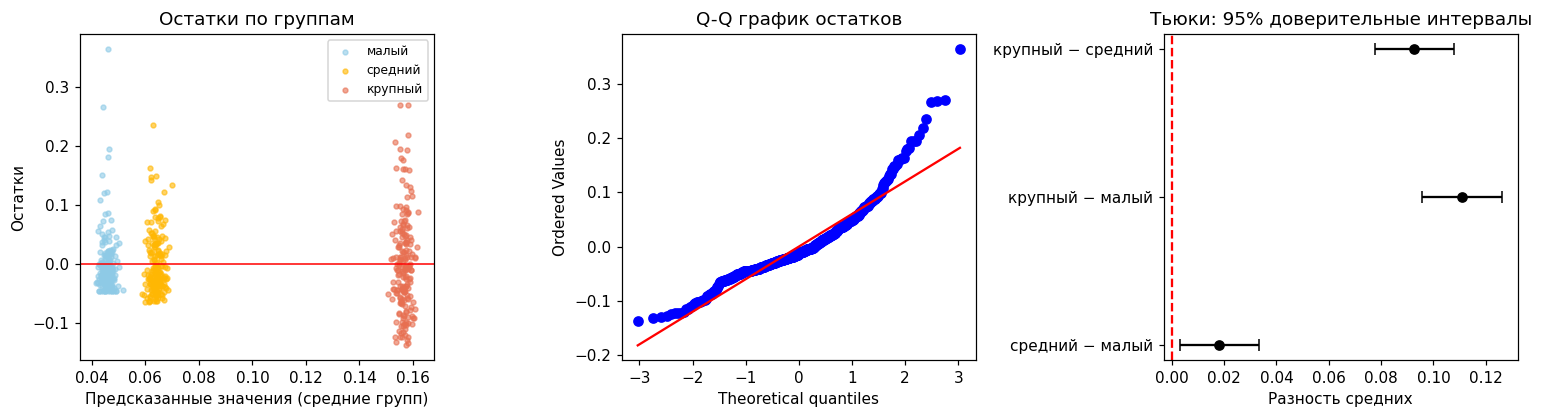

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
fitted = m1.fittedvalues
for s, c in zip(sz, ['#8ecae6', '#ffb703', '#e76f51']):
    idx = df['size'] == s
    ax[0].scatter(fitted[idx] + rng.normal(0, 0.002, idx.sum()), res[idx], s=10, alpha=0.6, color=c, label=s)
ax[0].axhline(0, color='red', lw=1)
ax[0].set_xlabel('Предсказанные значения (средние групп)'); ax[0].set_ylabel('Остатки')
ax[0].set_title('Остатки по группам'); ax[0].legend(fontsize=8)

stats.probplot(res, dist='norm', plot=ax[1]); ax[1].set_title('Q-Q график остатков')

for i, r in tk.iterrows():
    ax[2].errorbar(r['разность'], i, xerr=[[r['разность'] - r['ДИ от']], [r['ДИ до'] - r['разность']]], fmt='o', capsize=4, color='black')
ax[2].set_yticks(range(len(tk))); ax[2].set_yticklabels(tk['пара'])
ax[2].axvline(0, color='red', ls='--'); ax[2].set_xlabel('Разность средних'); ax[2].set_title('Тьюки: 95% доверительные интервалы')
plt.tight_layout(); plt.show()

**Описание.** На первом графике остатки у крупных ядер разбросаны шире, чем у малых: это неоднородность дисперсий. На Q-Q графике остатков правый конец загибается вверх, что соответствует правой асимметрии. Доверительные интервалы Тьюки не пересекают ноль, поэтому все три различия значимы.

## Часть 4. Двухфакторный ANOVA

**Промпт:** Выведи таблицу, в которой для каждой комбинации диагноза и размера ядра указано число наблюдений. Покажи, сбалансирован ли план.

Факторы: A — диагноз (2 уровня), B — размер ядра (3 уровня), отклик — mean_concavity. Проверяются гипотезы: H0(A) — средняя вогнутость одинакова при обоих диагнозах, H0(B) — одинакова для всех размеров, H0(A×B) — взаимодействия нет (разница между диагнозами не зависит от размера).

In [12]:
print(df.groupby(['diagnosis', 'size']).size().unstack()[sz])

size       малый  средний  крупный
diagnosis                         
benign       185      149       23
malignant      6       39      167


**Описание.** План сильно несбалансирован: у benign 185, 149 и 23 наблюдения, у malignant 6, 39 и 167. Крупные ядра встречаются почти только при злокачественных опухолях, а в ячейке «malignant, малый» всего 6 наблюдений. Из-за несбалансированности я использую суммы квадратов типа II.

**Промпт:** Построй двухфакторный ANOVA mean_concavity ~ diagnosis * size с суммами квадратов типа II, выведи таблицу эффектов A, B и A×B со средними квадратами и частными eta².

In [13]:
m2 = smf.ols('mean_concavity ~ C(diagnosis) * C(size)', data=df).fit()      # «*» = главные эффекты + взаимодействие
a2 = anova_lm(m2, typ=2)                                                      # тип II для несбалансированного плана
a2['MS'] = a2['sum_sq'] / a2['df']
a2['partial_eta2'] = a2['sum_sq'] / (a2['sum_sq'] + a2.loc['Residual', 'sum_sq'])   # частный eta²
a2.rename(index={'C(diagnosis)': 'A (диагноз)', 'C(size)': 'B (размер ядра)', 'C(diagnosis):C(size)': 'A×B (взаимодействие)'}).round(4)

,sum_sq,df,F,PR(>F),MS,partial_eta2
A (диагноз),0.4655,1.0,146.9723,0.0000,0.4655,0.2070
B (размер ядра),0.0614,2.0,9.6902,0.0001,0.0307,0.0333
A×B (взаимодействие),0.0147,2.0,2.3149,0.0997,0.0073,0.0082
Residual,1.7833,563.0,NaN,NaN,0.0032,0.5000


**Описание.** Формула `diagnosis * size` включает оба главных эффекта и их взаимодействие. Частный η² показывает долю изменчивости, объясняемую эффектом при учёте остальных.

Диагноз: F = 146,97, p < 0,001, частный η² = 0,207, сильный эффект. Размер ядра: F = 9,69, p < 0,001, но частный η² всего 0,033, тогда как в однофакторном анализе η² был 0,373. После учёта диагноза эффект размера мал, потому что крупные ядра чаще встречаются при злокачественных опухолях (167 из 190), то есть размер и диагноз смешаны (конфаундинг). Взаимодействие: F = 2,31, p = 0,100, на уровне 0,05 не значимо.

**Промпт:** Проверь предпосылки двухфакторной модели: нормальность остатков (Шапиро–Уилк) и однородность дисперсий в ячейках (Левен по медиане). Затем повтори ANOVA с робастными стандартными ошибками HC3, которые не требуют равенства дисперсий.

In [14]:
cells = [g.values for _, g in df.groupby(['diagnosis', 'size'])['mean_concavity']]
print(f'Шапиро (остатки): p = {stats.shapiro(m2.resid).pvalue:.1e}')
print(f'Левен (ячейки, по медиане): p = {stats.levene(*cells, center="median").pvalue:.1e}')

a2r = anova_lm(m2, typ=2, robust='hc3')           # робастные ошибки HC3
print(a2r[['F', 'PR(>F)']].rename(index={'C(diagnosis)': 'A (диагноз)', 'C(size)': 'B (размер)', 'C(diagnosis):C(size)': 'A×B'}).round(4))

Шапиро (остатки): p = 1.4e-20
Левен (ячейки, по медиане): p = 4.9e-14
                    F  PR(>F)
A (диагноз)  271.2889  0.0000
B (размер)     9.8802  0.0001
A×B            4.3652  0.0131
Residual          NaN     NaN


**Описание.** Остатки двухфакторной модели не нормальны, дисперсии в ячейках различаются (p < 0,001 в обоих случаях). Поэтому я повторила анализ с робастными ошибками HC3. Диагноз значим в обоих вариантах (F = 271,3 в робастном). Для взаимодействия результат меняется: классический ANOVA даёт p = 0,100, робастный p = 0,013. Следовательно, вывод о взаимодействии зависит от метода, и я считаю его предварительным. Вывод о влиянии диагноза устойчив.

**Промпт:** Выведи средние, стандартные отклонения и число наблюдений вогнутости по каждой комбинации диагноза и размера ядра и построй interaction plot: по оси X размер ядра, две линии для диагнозов, вертикальные отрезки — 95% доверительные интервалы средних.

diagnosis    size  mean   std  count
   benign крупный 0.059 0.025     23
   benign   малый 0.043 0.048    185
   benign средний 0.048 0.039    149
malignant крупный 0.170 0.078    167
malignant   малый 0.138 0.072      6
malignant средний 0.124 0.048     39


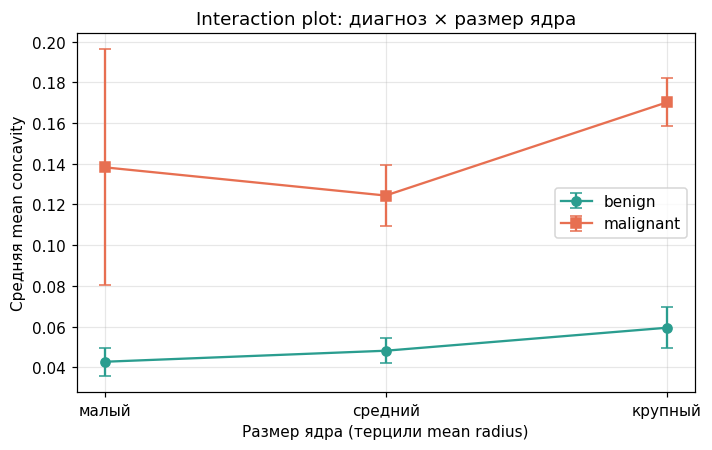

In [15]:
cm = df.groupby(['diagnosis', 'size'])['mean_concavity'].agg(['mean', 'std', 'count']).reset_index()
print(cm.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.6, 4.2))
for g, c, mk in [('benign', '#2a9d8f', 'o'), ('malignant', '#e76f51', 's')]:
    sub = cm[cm.diagnosis == g].set_index('size').loc[sz]
    se = sub['std'] / np.sqrt(sub['count'])
    ax.errorbar(range(3), sub['mean'], yerr=1.96 * se, marker=mk, capsize=4, color=c, label=g)
ax.set_xticks(range(3)); ax.set_xticklabels(sz)
ax.set_xlabel('Размер ядра (терцили mean radius)'); ax.set_ylabel('Средняя mean concavity')
ax.set_title('Interaction plot: диагноз × размер ядра'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Описание.** Interaction plot показывает средние по ячейкам: параллельные линии означают отсутствие взаимодействия, непараллельные — его наличие. У malignant вогнутость на всех размерах выше, чем у benign: разница 0,095; 0,076 и 0,111 для малых, средних и крупных ядер. Линии не строго параллельны, но широкий доверительный интервал у ячейки «malignant, малый» объясняется шестью наблюдениями. Поэтому вывод о взаимодействии неустойчив.

## Часть 5. Сравнительный анализ

**Промпт:** Методом Монте-Карло (5000 повторов, α = 0,05, нулевая гипотеза верна) оцени реальную долю ложных отклонений критериев Стьюдента, Уэлча и Манна–Уитни в трёх сценариях: нормальные данные с равными дисперсиями и объёмами (20 и 20); нормальные данные с σ = 3 и 1 при n = 10 и 40; сильно скошенные (логнормальные) данные при n = 15 и 15. Результат выведи таблицей.

Идея: на реальных данных эффекты либо огромные, либо нулевые, и все критерии дают один вывод. Чтобы увидеть разницу между критериями, я сам создаю данные, где различий нет, и считаю, как часто критерий ошибочно находит различие. Номинальный уровень равен 0,05.

In [16]:
NS = 5000                                           # число повторов моделирования
rng = np.random.default_rng(43)                    # отдельный генератор для моделирования

def two_group(s1, s2):
    r = {'Стьюдент': 0, 'Уэлч': 0, 'Манн–Уитни': 0}
    for _ in range(NS):
        x, z = s1(), s2()
        r['Стьюдент'] += stats.ttest_ind(x, z, equal_var=True).pvalue < 0.05
        r['Уэлч'] += stats.ttest_ind(x, z, equal_var=False).pvalue < 0.05
        r['Манн–Уитни'] += stats.mannwhitneyu(x, z, alternative='two-sided').pvalue < 0.05
    return {k: v / NS for k, v in r.items()}

sens = pd.DataFrame({
    'A: нормальные, равные σ и n (20/20)':    two_group(lambda: rng.normal(0, 1, 20), lambda: rng.normal(0, 1, 20)),
    'B: σ = 3 и 1, n = 10 и 40':               two_group(lambda: rng.normal(0, 3, 10), lambda: rng.normal(0, 1, 40)),
    'C: логнормальные (скошенные), n = 15/15': two_group(lambda: rng.lognormal(0, 1.2, 15), lambda: rng.lognormal(0, 1.2, 15)),
}).T
sens.round(3)

,Стьюдент,Уэлч,Манн–Уитни
"A: нормальные, равные σ и n (20/20)",0.048,0.048,0.049
"B: σ = 3 и 1, n = 10 и 40",0.251,0.047,0.128
"C: логнормальные (скошенные), n = 15/15",0.031,0.026,0.044


**Описание.** В каждом сценарии 5000 раз генерируются две выборки из одного и того же закона (различий нет), и считается доля случаев, когда критерий выдал p < 0,05. Это фактическая вероятность ошибки первого рода.

Сценарий A (все условия выполнены): все критерии около 0,05. Сценарий B (неравные дисперсии и объёмы, у меньшей группы разброс больше): критерий Стьюдента ошибается в 25% случаев вместо 5%, критерий Уэлча держит уровень (0,047), критерий Манна–Уитни ошибается в 13%, потому что он сравнивает распределения, а не средние. Сценарий C (скошенные данные): доли около 0,03–0,04, критерии слегка консервативны. Сценарий B похож на реальные данные по радиусу (меньшая группа malignant с большим разбросом), поэтому критерий Уэлча там предпочтительнее.

**Промпт:** Сделай такое же моделирование для ANOVA: обычный F-критерий, ANOVA Уэлча и критерий Краскела–Уоллиса для трёх групп, когда нулевая гипотеза верна. Два сценария: равные σ и n (20, 20, 20) и σ = 3, 2, 1 при n = 10, 20, 40.

In [17]:
def anova_sim(ns_, sds_):
    r = {'ANOVA (F)': 0, 'ANOVA Уэлча': 0, 'Краскел–Уоллис': 0}
    for _ in range(NS):
        gs = [rng.normal(0, s_, n_) for n_, s_ in zip(ns_, sds_)]
        r['ANOVA (F)'] += stats.f_oneway(*gs).pvalue < 0.05
        r['ANOVA Уэлча'] += anova_oneway(gs, use_var='unequal', welch_correction=True).pvalue < 0.05
        r['Краскел–Уоллис'] += stats.kruskal(*gs).pvalue < 0.05
    return {k: v / NS for k, v in r.items()}

sens_a = pd.DataFrame({
    'равные σ и n (20, 20, 20)': anova_sim([20, 20, 20], [1, 1, 1]),
    'σ = 3, 2, 1 при n = 10, 20, 40': anova_sim([10, 20, 40], [3, 2, 1]),
}).T
sens_a.round(3)

,ANOVA (F),ANOVA Уэлча,Краскел–Уоллис
"равные σ и n (20, 20, 20)",0.051,0.052,0.053
"σ = 3, 2, 1 при n = 10, 20, 40",0.200,0.054,0.120


**Описание.** Для трёх групп картина та же. При равных дисперсиях и объёмах все критерии держат уровень 0,05. При неравных дисперсиях и объёмах обычный ANOVA ошибается в 20% случаев, Краскел–Уоллис в 12%, а ANOVA Уэлча остаётся около 0,05 (0,054). Вывод: при неоднородных дисперсиях нужно использовать варианты Уэлча.

**Промпт:** Посчитай, сколько наблюдений нужно в каждой группе для мощности 0,8 при α = 0,05: для t-критерия при малом, среднем и большом эффекте (d = 0,2; 0,5; 0,8) и для ANOVA с тремя группами (f = 0,1; 0,25; 0,4).

In [18]:
pw = TTestIndPower()
for d_, name in [(0.2, 'малый'), (0.5, 'средний'), (0.8, 'большой')]:
    n_need = int(np.ceil(pw.solve_power(effect_size=d_, power=0.8, alpha=0.05)))
    print(f't-критерий, d = {d_} ({name}): нужно {n_need} наблюдений в каждой группе')

fp = FTestAnovaPower()
for f_, name in [(0.1, 'малый'), (0.25, 'средний'), (0.4, 'большой')]:
    n_tot = fp.solve_power(effect_size=f_, power=0.8, alpha=0.05, k_groups=3)
    print(f'ANOVA (3 группы), f = {f_} ({name}): нужно {int(np.ceil(n_tot / 3))} наблюдений в каждой группе')

t-критерий, d = 0.2 (малый): нужно 394 наблюдений в каждой группе
t-критерий, d = 0.5 (средний): нужно 64 наблюдений в каждой группе
t-критерий, d = 0.8 (большой): нужно 26 наблюдений в каждой группе
ANOVA (3 группы), f = 0.1 (малый): нужно 323 наблюдений в каждой группе
ANOVA (3 группы), f = 0.25 (средний): нужно 53 наблюдений в каждой группе
ANOVA (3 группы), f = 0.4 (большой): нужно 22 наблюдений в каждой группе


**Описание.** Мощность — вероятность обнаружить эффект, если он действительно есть. Функция `solve_power` находит объём выборки, при котором мощность равна 0,8. Чем меньше эффект, тем больше нужна выборка: для среднего эффекта (d = 0,5) 64 наблюдения в группе, для малого (d = 0,2) 394, для большого (d = 0,8) 26. Для ANOVA с тремя группами: 323, 53 и 22 наблюдения в группе.

**Промпт:** Оцени мощность на реальных данных. Возьми признак mean_smoothness, посчитай d Коэна между benign и malignant, найди расчётный объём выборки для мощности 0,8. Затем для размеров подвыборки 3, 5, 8, 10, 15, 20, 30, 50, 80 по 2000 раз случайно выбери подвыборки из каждой группы и посчитай долю отклонений H0 для t-критерия и критерия Манна–Уитни. Рядом выведи теоретическую мощность.

In [19]:
ta = df.loc[df.diagnosis == 'benign', 'mean_smoothness'].values
tb = df.loc[df.diagnosis == 'malignant', 'mean_smoothness'].values
sp_ = np.sqrt(((len(ta) - 1) * ta.var(ddof=1) + (len(tb) - 1) * tb.var(ddof=1)) / (len(ta) + len(tb) - 2))
d_sm = (tb.mean() - ta.mean()) / sp_
print(f'mean_smoothness: средние {ta.mean():.4f} и {tb.mean():.4f}, d = {d_sm:.2f}; расчётный объём {int(np.ceil(pw.solve_power(effect_size=d_sm, power=0.8, alpha=0.05)))} в группе')

rows = []
for m_ in [3, 5, 8, 10, 15, 20, 30, 50, 80]:
    rt = rm = 0
    for _ in range(2000):
        x = rng.choice(ta, m_, replace=False); z = rng.choice(tb, m_, replace=False)   # случайные подвыборки по m_ пациенток
        rt += stats.ttest_ind(x, z).pvalue < 0.05
        rm += stats.mannwhitneyu(x, z, alternative='two-sided').pvalue < 0.05
    rows.append({'n в группе': m_, 't-критерий': rt / 2000, 'Манн–Уитни': rm / 2000,
                 'расчёт': pw.power(effect_size=d_sm, nobs1=m_, alpha=0.05)})
pd.DataFrame(rows).round(3)

mean_smoothness: средние 0.0925 и 0.1029, d = 0.79; расчётный объём 26 в группе


,n в группе,t-критерий,Манн–Уитни,расчёт
0,3,0.120,0.000,0.118
1,5,0.205,0.144,0.198
2,8,0.334,0.333,0.315
3,10,0.418,0.388,0.389
4,15,0.572,0.558,0.555
5,20,0.714,0.711,0.686
6,30,0.875,0.885,0.855
7,50,0.986,0.988,0.975
8,80,0.999,0.999,0.999


**Описание.** Для признака `mean_smoothness` различие между диагнозами умеренное (d = 0,79, средние 0,0925 и 0,1029), расчётный объём для мощности 0,8 равен 26 наблюдениям в группе. Таблица показывает, как мощность растёт с размером подвыборки: при 20 наблюдениях около 71%, при 30 около 88%, при 50 около 98%. Эксперимент совпадает с теоретическим расчётом. При 3 наблюдениях в группе t-критерий находит различие примерно в 12% случаев, а критерий Манна–Уитни не находит никогда: для выборок 3 + 3 наименьшее возможное p-value равно 0,1, поэтому ранговый критерий принципиально не может достичь значимости.

## Выводы

1. Для работы использован набор Breast Cancer Wisconsin: 569 наблюдений (357 доброкачественных и 212 злокачественных опухолей), пропусков нет. Дисперсии неоднородны (СКО радиуса 1,78 и 3,20), вогнутость контура скошена вправо.
2. Для двух групп (benign и malignant) радиус ядра при злокачественной опухоли больше на 5,32; все три критерия (Стьюдента, Уэлча, Манна–Уитни) отвергают H0 (p < 0,001), d = 2,21. Из-за неравных дисперсий и объёмов групп корректнее критерий Уэлча. По фрактальной размерности различий нет (p ≈ 0,77, d = −0,03, узкий доверительный интервал). Парные критерии (t и Уилкоксона) отвергают H0; разности скошены, поэтому надёжнее критерий Уилкоксона.
3. Однофакторный ANOVA по размеру ядра значим: F = 168,3, p < 0,001, η² = 0,373, ω² = 0,370. Вывод подтверждён ANOVA Уэлча и критерием Краскела–Уоллиса, то есть нарушение предпосылок его не изменило. Пост-хок критерии (Тьюки, Бонферрони, Даннета) выявили различия во всех парах; основной рост вогнутости приходится на крупные ядра.
4. В двухфакторном ANOVA диагноз имеет сильный эффект (частный η² = 0,207), эффект размера ядра после учёта диагноза мал (частный η² = 0,033 против 0,373 без учёта диагноза, это следствие смешения факторов). Взаимодействие не значимо в классическом анализе (p = 0,100) и значимо в робастном (p = 0,013), поэтому вывод о нём неустойчив.
5. Моделирование показало, что при неравных дисперсиях и объёмах групп классические критерии завышают ошибку первого рода (до 25% у t-критерия и 20% у ANOVA), критерии Уэлча держат уровень 0,05, а непараметрические критерии от этого не защищают. Для среднего эффекта (d = 0,5) для мощности 0,8 нужно 64 наблюдения в каждой группе.

Ограничения: фактор «размер ядра» построен мной из данных и не является экспериментальным; план двухфакторного анализа несбалансирован (в одной ячейке 6 наблюдений); парное сравнение worst и mean radius тривиально по смыслу.